In [1]:
import pandas as pd

In [29]:
path_meta = '../data/raw/metadata.csv'
df = pd.read_csv(path_meta)

In [6]:
df.head()

,building_id,site_id,building_id_kaggle,site_id_kaggle,primaryspaceusage,sub_primaryspaceusage,sqm,sqft,lat,lng,...,yearbuilt,date_opened,numberoffloors,occupants,energystarscore,eui,site_eui,source_eui,leed_level,rating
0,Panther_lodging_Dean,Panther,NaN,0.0,Lodging/residential,Residence Hall,508.8,5477.0,28.517689,-81.379039,...,1989.0,NaN,NaN,NaN,NaN,271,NaN,NaN,NaN,NaN
1,Panther_lodging_Shelia,Panther,NaN,0.0,Lodging/residential,Residence Hall,929.0,10000.0,28.517689,-81.379039,...,1992.0,NaN,NaN,NaN,NaN,62,NaN,NaN,NaN,NaN
2,Panther_lodging_Ricky,Panther,NaN,0.0,Lodging/residential,Residence Hall,483.1,5200.0,28.517689,-81.379039,...,2016.0,NaN,NaN,NaN,NaN,534,NaN,NaN,NaN,NaN
3,Panther_education_Rosalie,Panther,0.0,0.0,Education,Research,690.5,7432.0,28.517689,-81.379039,...,2008.0,NaN,NaN,NaN,NaN,276,NaN,NaN,NaN,NaN
4,Panther_education_Misty,Panther,1.0,0.0,Education,Research,252.7,2720.0,28.517689,-81.379039,...,2004.0,NaN,NaN,NaN,NaN,375,NaN,NaN,NaN,NaN


In [7]:
rows, cols = df.shape   

In [8]:
print(rows, cols)

1636 32


In [17]:
df["electricity"].value_counts(dropna=False)

electricity
Yes    1578
NaN      58
Name: count, dtype: int64

In [18]:
elec = df[df["electricity"] == "Yes"]

In [19]:
len(elec)

1578

In [21]:
elec["site_id"].value_counts(dropna=False)

site_id
Rat         305
Hog         152
Lamb        146
Fox         137
Bull        123
Cockatoo    117
Eagle       106
Panther     105
Bear         92
Gator        74
Robin        52
Peacock      45
Wolf         36
Bobcat       35
Swan         19
Moose        13
Shrew         9
Mouse         7
Crow          5
Name: count, dtype: int64

In [22]:
df[["site_id", "timezone"]]

,site_id,timezone
0,Panther,US/Eastern
1,Panther,US/Eastern
2,Panther,US/Eastern
3,Panther,US/Eastern
4,Panther,US/Eastern
...,...,...
1631,Mouse,Europe/London
1632,Mouse,Europe/London
1633,Mouse,Europe/London
1634,Mouse,Europe/London


In [23]:
df[["site_id","timezone"]].drop_duplicates()

,site_id,timezone
0,Panther,US/Eastern
136,Robin,Europe/London
188,Fox,US/Mountain
325,Rat,US/Eastern
630,Bear,US/Pacific
722,Lamb,Europe/London
869,Peacock,US/Eastern
916,Moose,US/Eastern
931,Gator,US/Eastern
1005,Bull,US/Central


In [27]:
Time_zone = df[["site_id","timezone"]].drop_duplicates()

In [28]:
Time_zone["timezone"].value_counts()

timezone
US/Eastern       8
Europe/London    4
US/Mountain      2
US/Pacific       2
US/Central       2
Europe/Dublin    1
Name: count, dtype: int64

In [156]:
path_elec = '../data/raw/electricity_cleaned.csv'
df_elec = pd.read_csv(path_elec , parse_dates=["timestamp"])

In [157]:
df_elec.shape

(17544, 1579)

In [158]:
df_elec.head()

,timestamp,Panther_parking_Lorriane,Panther_lodging_Cora,Panther_office_Hannah,Panther_lodging_Hattie,Panther_education_Teofila,Panther_education_Jerome,Panther_retail_Felix,Panther_parking_Asia,Panther_education_Misty,...,Cockatoo_public_Caleb,Cockatoo_education_Tyler,Cockatoo_public_Shad,Mouse_health_Buddy,Mouse_health_Modesto,Mouse_lodging_Vicente,Mouse_health_Justin,Mouse_health_Ileana,Mouse_health_Estela,Mouse_science_Micheal
0,2016-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,123.200,727.575,69.200,8.8224,370.0870,10.0,282.9965,26.0,135.0,168.2243
1,2016-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,126.475,731.200,66.275,17.6449,737.8260,30.0,574.9265,51.0,265.0,336.4486
2,2016-01-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,127.825,724.675,64.675,17.6449,729.9255,30.0,570.2780,50.0,272.0,336.4486
3,2016-01-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,130.475,737.375,65.875,17.6449,722.2620,20.0,561.1470,52.0,276.0,336.4486
4,2016-01-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,129.675,721.150,66.275,17.6449,719.1665,30.0,564.3695,50.0,280.0,336.4486


In [159]:
df_elec["timestamp"].min()

Timestamp('2016-01-01 00:00:00')

In [160]:
df_elec["timestamp"].max()

Timestamp('2017-12-31 23:00:00')

In [161]:
df_elec = df_elec.set_index("timestamp")
missing = df_elec.isna().mean()

In [162]:
sorted_missing = missing.sort_values(ascending=False)

In [163]:
sorted_missing.head(10)

Eagle_assembly_Noel        1.000000
Hog_assembly_Arlie         1.000000
Hog_assembly_Marilynn      1.000000
Hog_assembly_Una           1.000000
Eagle_lodging_Garland      1.000000
Rat_public_Ulysses         1.000000
Hog_parking_Joan           0.999886
Gator_assembly_Elliot      0.998632
Bobcat_education_Barbra    0.993730
Hog_assembly_Annemarie     0.985522
dtype: float64

In [164]:
x = (missing > 0.05)
print(x)

Panther_parking_Lorriane     True
Panther_lodging_Cora         True
Panther_office_Hannah        True
Panther_lodging_Hattie       True
Panther_education_Teofila    True
                             ... 
Mouse_lodging_Vicente        True
Mouse_health_Justin          True
Mouse_health_Ileana          True
Mouse_health_Estela          True
Mouse_science_Micheal        True
Length: 1578, dtype: bool


In [165]:
missing.mean()

np.float64(0.08928675148545578)

In [166]:
missing.median()

np.float64(0.011200410396716827)

In [167]:
missing_2016 = df_elec.loc["2016"].isna().mean()
# missing_2016

In [168]:
missing_2017 = df_elec.loc["2017"].isna().mean()
# missing_2017

In [169]:
site = missing.index.str.split("_").str[0]
total = missing.groupby(site).size()
rows = {}
for t in [0.05, 0.10, 0.20, 0.50]:
    kept = missing[missing <= t]                      # keep buildings with missing <= t
    kept_site = kept.index.str.split("_").str[0]
    rows[t] = kept.groupby(kept_site).size().reindex(total.index, fill_value=0)
table_total = pd.DataFrame(rows)
table_total["total"] = total
# table_total

In [170]:
site = missing_2016.index.str.split("_").str[0]
total = missing_2016.groupby(site).size()
rows = {}
for t in [0.05, 0.10, 0.20, 0.50]:
    kept = missing_2016[missing_2016 <= t]                      # keep buildings with missing <= t
    kept_site = kept.index.str.split("_").str[0]
    rows[t] = kept.groupby(kept_site).size().reindex(total.index, fill_value=0)
table_2016 = pd.DataFrame(rows)
table_2016["total"] = total
# table_2016

In [171]:
totalsite = missing_2017.index.str.split("_").str[0]
total = missing_2017.groupby(site).size()
rows = {}
for t in [0.05, 0.10, 0.20, 0.50]:
    kept = missing_2017[missing_2017 <= t]                      # keep buildings with missing <= t
    kept_site = kept.index.str.split("_").str[0]
    rows[t] = kept.groupby(kept_site).size().reindex(total.index, fill_value=0)
table_2017 = pd.DataFrame(rows)
table_2017["total"] = total
# table_2017

In [172]:
compare = pd.concat(
    [table_total, table_2016, table_2017],
    axis=1,
    keys=["total", "2016", "2017"]
)
compare

total                      2016                      2017            \
          0.05  0.1  0.2  0.5 total 0.05  0.1  0.2  0.5 total 0.05  0.1  0.2   
Bear        78   80   85   92    92   78   78   81   86    92   89   91   91   
Bobcat       0   12   22   27    35   21   21   24   28    35    0    0   15   
Bull       109  117  119  123   123  114  115  120  122   123  115  117  122   
Cockatoo     0  104  109  114   117    0    0  108  113   117  108  110  112   
Crow         0    4    5    5     5    5    5    5    5     5    0    0    4   
Eagle       75   93   98  101   106   66   93   96  102   106   78   97  100   
Fox        128  131  134  135   137  129  132  133  136   137  131  133  134   
Gator       21   58   62   70    74   22   40   66   69    74   44   61   65   
Hog        136  137  140  143   152  139  140  140  140   152  140  140  141   
Lamb        83  124  132  144   146  127  137  140  143   146   85   85  133   
Moose        9    9    9   12    13   10   10   10   11    13   11   11   11   
Mouse        0    4    5    5     7    5    5    5    7     7    0    0    4   
Panther      0    0   93  105   105    0    0    0  103   105  101  105  105   
Peacock     36   36   36   36    45   36   36   36   36    45   36   36   43   
Rat        257  260  264  280   305  270  277  283  295   305  254  262  264   
Robin       51   51   51   51    52   51   51   52   52    52   51   51   51   
Shrew        0    0    0    9     9    9    9    9    9     9    0    0    0   
Swan         0    0    0    0    19    0    0    0    0    19   14   15   19   
Wolf        36   36   36   36    36   35   36   36   36    36   36   36   36   

                     
          0.5 total  
Bear       91    92  
Bobcat     26    35  
Bull      122   123  
Cockatoo  114   117  
Crow        5     5  
Eagle     102   106  
Fox       136   137  
Gator      66    74  
Hog       146   152  
Lamb      134   146  
Moose      11    13  
Mouse       5     7  
Panther   105   105  
Peacock    44    45  
Rat       271   305  
Robin      51    52  
Shrew       0     9  
Swan       19    19  
Wolf       36    36

In [173]:
for t in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.35]:
    kept = missing[(missing_2016 <= t) & (missing_2017 <= t)]
    kept_site = kept.index.str.split("_").str[0]
    rows[t] = kept.groupby(kept_site).size().reindex(total.index, fill_value=0)
table = pd.DataFrame(rows)
table["total"] = total
tablefor t in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.35]:
    kept = missing[(missing_2016 <= t) & (missing_2017 <= t)]
    kept_site = kept.index.str.split("_").str[0]
    rows[t] = kept.groupby(kept_site).size().reindex(total.index, fill_value=0)
table = pd.DataFrame(rows)
table["total"] = total
table

SyntaxError: invalid syntax (4251405638.py, line 7)

<Axes: >

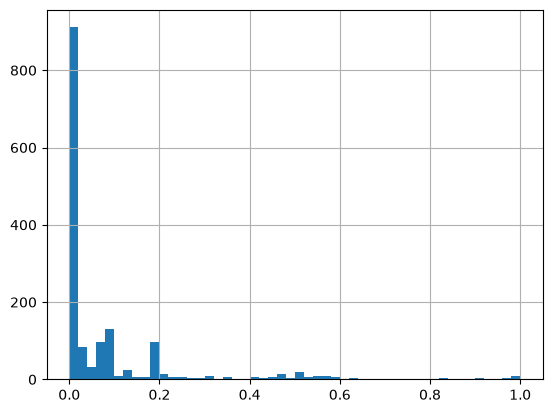

In [174]:
missing.hist(bins=50)

In [125]:
panther_cols = [c for c in df_elec.columns if c.startswith("Panther_")]
len(panther_cols), panther_cols[:5]

(105,
 ['Panther_parking_Lorriane',
  'Panther_lodging_Cora',
  'Panther_office_Hannah',
  'Panther_lodging_Hattie',
  'Panther_education_Teofila'])

In [126]:
df_elec[panther_cols[0]].first_valid_index()

Timestamp('2016-02-01 03:00:00')

In [127]:
starts = df_elec[panther_cols].apply(lambda col: col.first_valid_index())
starts.value_counts()

2016-05-01 19:00:00    60
2016-01-01 00:00:00     3
2016-02-01 03:00:00     1
2016-01-02 19:00:00     1
2016-02-17 22:00:00     1
2016-01-31 19:00:00     1
2016-01-02 13:00:00     1
2016-06-30 13:00:00     1
2016-01-04 13:00:00     1
2016-03-04 07:00:00     1
2016-01-20 23:00:00     1
2016-01-07 16:00:00     1
2016-01-29 23:00:00     1
2016-01-01 11:00:00     1
2016-01-02 17:00:00     1
2016-01-10 21:00:00     1
2016-01-01 19:00:00     1
2016-01-04 17:00:00     1
2016-02-01 08:00:00     1
2016-01-02 23:00:00     1
2016-01-30 08:00:00     1
2016-01-30 17:00:00     1
2016-01-01 01:00:00     1
2016-03-29 18:00:00     1
2016-01-02 07:00:00     1
2016-06-03 11:00:00     1
2016-02-07 13:00:00     1
2016-01-22 05:00:00     1
2016-01-26 19:00:00     1
2016-02-11 16:00:00     1
2016-01-02 09:00:00     1
2016-01-02 03:00:00     1
2016-01-03 23:00:00     1
2016-01-14 17:00:00     1
2016-01-30 21:00:00     1
2016-02-15 09:00:00     1
2016-01-25 17:00:00     1
2016-01-23 17:00:00     1
2016-01-01 0

Panther 105 buildings
start:
 2016-05-01 19:00:00    60
2016-01-01 00:00:00     3
2016-02-01 03:00:00     1
2016-01-02 19:00:00     1
2016-02-17 22:00:00     1
Name: count, dtype: int64
end:
 2017-12-31 23:00:00    102
2017-12-05 12:00:00      1
2017-12-16 07:00:00      1
2017-12-18 14:00:00      1
Name: count, dtype: int64 

Swan 19 buildings
start:
 2017-01-03 07:00:00    9
2017-01-03 09:00:00    6
2017-01-03 10:00:00    3
2017-01-01 01:00:00    1
Name: count, dtype: int64
end:
 2017-12-31 23:00:00    19
Name: count, dtype: int64 

Shrew 9 buildings
start:
 2016-01-01    9
Name: count, dtype: int64
end:
 2017-01-25 23:00:00    6
2017-01-24 23:00:00    2
2017-03-29 00:00:00    1
Name: count, dtype: int64 



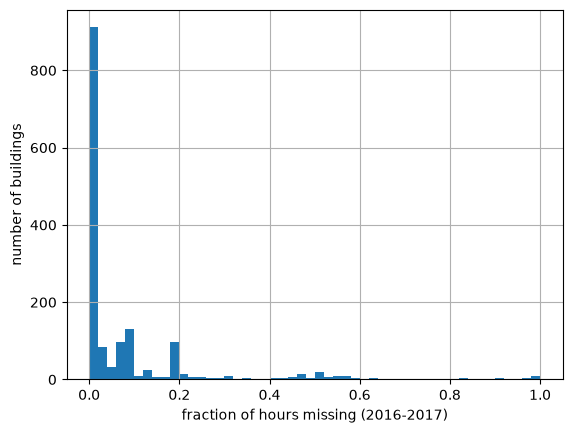

In [128]:
import matplotlib.pyplot as plt

# 1. When does each site's data start and end?
for site in ["Panther", "Swan", "Shrew"]:
    cols = [c for c in df_elec.columns if c.startswith(site + "_")]
    starts = df_elec[cols].apply(lambda col: col.first_valid_index())
    ends = df_elec[cols].apply(lambda col: col.last_valid_index())
    print(site, len(cols), "buildings")
    print("start:\n", starts.value_counts().head())
    print("end:\n", ends.value_counts().head(), "\n")

# 2. Shape of missing data over all buildings
missing.hist(bins=50)
plt.xlabel("fraction of hours missing (2016-2017)")
plt.ylabel("number of buildings")
plt.show()

In [132]:
t = 0.20
kept = missing[(missing_2016 <= t) & (missing_2017 <= t)]
kept_site = kept.index.str.split("_").str[0]
rows[t] = kept.groupby(kept_site).size().reindex(total.index, fill_value=0)
table_20 = pd.DataFrame(rows)
table_20["total"] = total
table_20

,0.05,0.1,0.2,0.5,0.3,0.4,0.35,total
Bear,77,78,81,85,83,85,84,92
Bobcat,0,0,13,26,24,25,25,35
Bull,107,109,119,121,119,119,119,123
Cockatoo,0,0,107,113,111,113,111,117
Crow,0,0,4,5,5,5,5,5
Eagle,63,89,94,100,97,100,97,106
Fox,125,130,131,135,134,134,134,137
Gator,18,36,61,64,64,64,64,74
Hog,135,136,137,140,140,140,140,152
Lamb,79,83,130,133,131,133,132,146


In [135]:
# for the threshold I will use 0.20 which will be applied to each year separately, the year 2016 will be the training data and 2017 will 
# be the testing data
# from the table above it is seen how many buildings are remaining
# since panther and swan has no data in these threshold at 2016 there will be unseen datasets for 2017
# the dataset for shrew will be completely excluded because this site has no dataset in this threshold to test for 2017

In [136]:
t = 0.20
held_out = ("Panther_", "Swan_")
excluded = ("Shrew_",)

passes = missing_2016.index[(missing_2016 <= t) & (missing_2017 <= t)]
train_buildings = [b for b in passes if not b.startswith(held_out + excluded)]
train_sites = pd.Index(train_buildings).str.split("_").str[0]

print(len(train_buildings), "buildings,", train_sites.nunique(), "sites")
pd.Series(train_buildings).to_csv("../configs/train_buildings.csv", index=False, header=["building"])

1274 buildings, 16 sites


In [154]:

# Building filter. Keep a building if it has at most 20% missing hours in 2016 and at most 20% in 2017. This keeps 1274 buildings from 16 sites. Panther (meters started 1 May 2016) and Swan (data starts Jan 2017) are held out as unseen test sites, using 2017 only. Shrew is excluded because it has no data on 2017. Missing data comes in site-sized blocks, so they are not random.
# A small change in the threshold adds or removes a whole site (e.g. Cockatoo between 10% and 20%


In [138]:
weather = pd.read_csv("../data/raw/weather.csv", parse_dates=["timestamp"])
print(weather.shape)
print(weather.columns.tolist())
print(weather["site_id"].nunique(), "sites")
weather.groupby("site_id").apply(lambda g: g.isna().mean()).round(2)

(331166, 10)
['timestamp', 'site_id', 'airTemperature', 'cloudCoverage', 'dewTemperature', 'precipDepth1HR', 'precipDepth6HR', 'seaLvlPressure', 'windDirection', 'windSpeed']
19 sites


,timestamp,airTemperature,cloudCoverage,dewTemperature,precipDepth1HR,precipDepth6HR,seaLvlPressure,windDirection,windSpeed
site_id,,,,,,,,,
Bear,0.0,0.0,0.46,0.00,0.08,0.98,0.01,0.01,0.00
Bobcat,0.0,0.0,0.28,0.00,0.00,0.97,0.01,0.06,0.01
Bull,0.0,0.0,0.40,0.01,0.00,0.97,0.03,0.29,0.01
Cockatoo,0.0,0.0,0.54,0.00,0.79,0.94,0.07,0.03,0.00
Crow,0.0,0.0,1.00,0.00,0.90,0.83,0.00,0.00,0.00
Eagle,0.0,0.0,0.40,0.00,0.01,0.96,0.01,0.03,0.00
Fox,0.0,0.0,0.28,0.00,0.00,0.99,0.00,0.07,0.00
Gator,0.0,0.0,0.43,0.00,0.00,0.96,0.02,0.03,0.00
Hog,0.0,0.0,0.49,0.00,0.00,0.96,0.01,0.03,0.00


In [139]:
rows_per_site = weather.groupby("site_id").size()
print(rows_per_site)
print("expected:", len(df_elec))   # 17,544 hours in 2016-2017
print(weather.duplicated(["site_id", "timestamp"]).sum(), "duplicate rows")

site_id
Bear        17542
Bobcat      17525
Bull        17529
Cockatoo    16975
Crow        16860
Eagle       17536
Fox         17543
Gator       17544
Hog         17542
Lamb        17500
Moose       16860
Mouse       17516
Panther     17544
Peacock     17539
Rat         17539
Robin       17516
Shrew       17516
Swan        17535
Wolf        17505
dtype: int64
expected: 17544
0 duplicate rows


In [142]:


# Weather features. I keep airTemperature, windSpeed because air temperature drives heating and cooling demand, and wind speed increases heat loss through the building envelope. I drop precipDepth6HR and cloudCoverage because 83–99% missing everywhere and 25–100% missing and fully empty at Crow and Moose, respectively.
# We also keep dewTemperature because this controls the humidity, which drives cooling aid and the missing is 0-7%.
# precipDepth1HR and seaLvlPressure are also dropped because they are fully missing on some sites
# The main reason to keep or drop a feature is its existance on all the sites. Since we are using federated learning it is essential that one feature exist for all the sites because the model will be trained using that feature on all the tarning data.

# In addition, up to 24 hours gaps will be filled using time interpolation.
# The longer gaps for example Crow and Moose will be droped.
# These gaps are for Training (2016): only 39 hours, on 4–5 Jan. and for Test (2017): 89 + 32 + 202 = 323




In [143]:
full_hours = pd.date_range("2016-01-01 00:00", "2017-12-31 23:00", freq="h")
temp = weather.pivot(index="timestamp", columns="site_id", values="airTemperature").reindex(full_hours)

def longest_gap(s):
    na = s.isna()
    return na.groupby((~na).cumsum()).sum().max()

temp.apply(longest_gap).sort_values(ascending=False)

site_id
Crow        202
Moose       202
Bull         21
Cockatoo     14
Swan         12
Bobcat       11
Wolf         10
Lamb          8
Eagle         7
Mouse         5
Robin         5
Shrew         5
Peacock       4
Gator         3
Panther       3
Rat           2
Hog           1
Fox           1
Bear          1
dtype: int64

In [144]:

# Fill weather gaps of up to 24 hours by time interpolation.
# Leave longer gaps (only Crow and Moose) as missing, and drop those hours for those two sites. If the gap is in 2017, those hours are also skipped in the test metrics, and you say so.


In [145]:
na = temp["Crow"].isna()
gap_len = na.groupby((~na).cumsum()).transform("sum")
long_gap = temp.index[na & (gap_len > 24)]
print(long_gap.min(), "to", long_gap.max())

2016-01-04 01:00:00 to 2017-12-18 17:00:00


In [146]:
gap_id = (~na).cumsum()
hours = temp.index.to_series()[na]
gaps = hours.groupby(gap_id[na]).agg(["min", "max", "count"])
gaps[gaps["count"] > 24]

,min,max,count
Crow,,,
72,2016-01-04 01:00:00,2016-01-05 15:00:00,39
10372,2017-03-17 17:00:00,2017-03-21 09:00:00,89
16519,2017-12-07 14:00:00,2017-12-08 21:00:00,32
16544,2017-12-10 08:00:00,2017-12-18 17:00:00,202


In [148]:
(temp["Crow"].isna() == temp["Moose"].isna()).all()

np.True_

               building_id site_id       timezone
169  Robin_public_Carolina   Robin  Europe/London


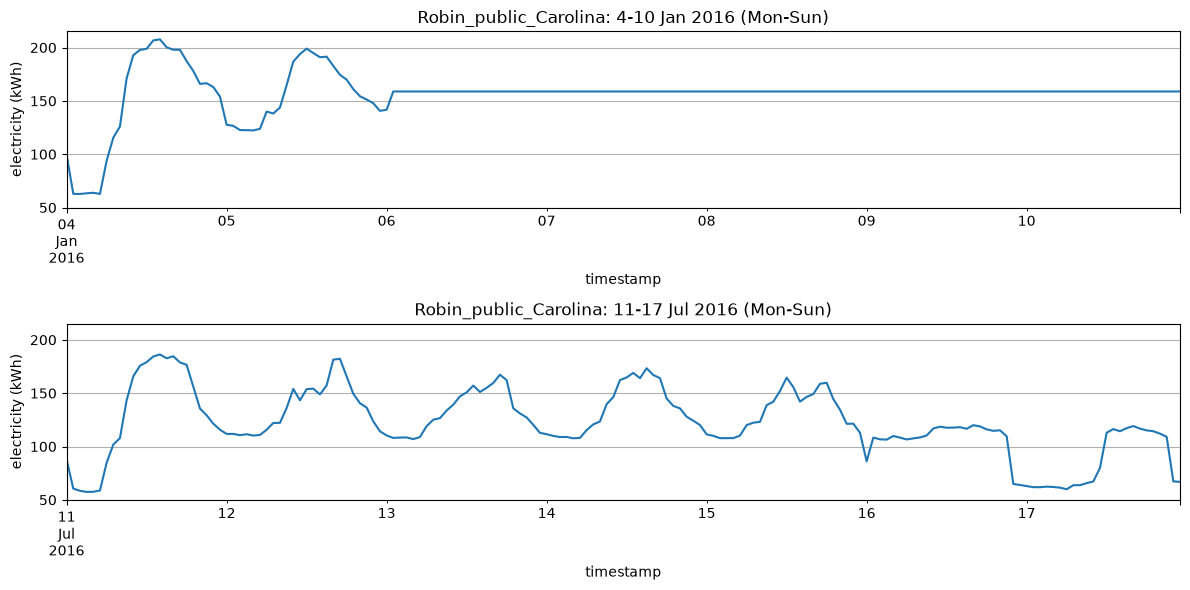

In [149]:
import matplotlib.pyplot as plt

meta = pd.read_csv("../data/raw/metadata.csv")
b = train_buildings[0]
print(meta.loc[meta["building_id"] == b, ["building_id", "site_id", "timezone"]])

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharey=True)
df_elec.loc["2016-01-04":"2016-01-10", b].plot(ax=axes[0], title=f"{b}: 4-10 Jan 2016 (Mon-Sun)")
df_elec.loc["2016-07-11":"2016-07-17", b].plot(ax=axes[1], title=f"{b}: 11-17 Jul 2016 (Mon-Sun)")
for ax in axes:
    ax.set_ylabel("electricity (kWh)")
    ax.grid(True)
plt.tight_layout()
plt.show()

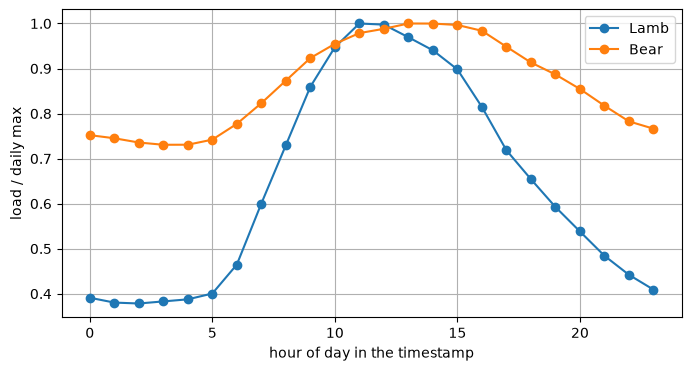

In [150]:
fig, ax = plt.subplots(figsize=(8, 4))
for site in ["Lamb", "Bear"]:
    cols = [c for c in train_buildings if c.startswith(site + "_")]
    site_load = df_elec.loc["2016", cols].mean(axis=1)
    profile = site_load.groupby(site_load.index.hour).mean()
    (profile / profile.max()).plot(ax=ax, marker="o", label=site)
ax.set_xlabel("hour of day in the timestamp")
ax.set_ylabel("load / daily max")
ax.legend()
ax.grid(True)
plt.show()

In [151]:
def longest_flat_run(s):
    same = s.diff().eq(0)
    return same.groupby((~same).cumsum()).sum().max()

flat = df_elec[train_buildings].apply(longest_flat_run)
print(flat.sort_values(ascending=False).head(10))
print((flat > 24).sum(), "buildings with a flat run longer than 24 hours")

Lamb_education_Willetta    8782
Robin_education_Della      7294
Lamb_education_Patsy       7198
Lamb_assembly_Delilah      7198
Lamb_education_Garry       7198
Lamb_education_Harold      7198
Lamb_office_Jo             7198
Lamb_education_Hillary     7198
Lamb_education_Isabelle    6382
Lamb_education_Maxwell     6382
dtype: int64
393 buildings with a flat run longer than 24 hours


In [152]:
# 1. How many buildings at each run length?
for h in [24, 48, 168, 720]:
    print(h, "hours:", (flat > h).sum(), "buildings")

# 2. For the top 10: what value is stuck, and when does it start?
def flat_info(s):
    same = s.diff().eq(0)
    run_len = same.groupby((~same).cumsum()).transform("sum")
    start = run_len.idxmax()
    return pd.Series({"value": s[start], "hours": run_len.max(), "start": start})

top = flat.sort_values(ascending=False).head(10).index
pd.DataFrame({b: flat_info(df_elec[b]) for b in top}).T

24 hours: 393 buildings
48 hours: 366 buildings
168 hours: 191 buildings
720 hours: 151 buildings


,value,hours,start
Lamb_education_Willetta,0.0004,8782,2016-01-01 01:00:00
Robin_education_Della,0.7492,7294,2016-01-01 01:00:00
Lamb_education_Patsy,0.0003,7198,2017-03-07 01:00:00
Lamb_assembly_Delilah,0.0002,7198,2017-03-07 01:00:00
Lamb_education_Garry,0.0003,7198,2017-03-07 01:00:00
Lamb_education_Harold,0.0003,7198,2017-03-07 01:00:00
Lamb_office_Jo,0.0002,7198,2017-03-07 01:00:00
Lamb_education_Hillary,0.0002,7198,2017-03-07 01:00:00
Lamb_education_Isabelle,0.0009,6382,2017-03-07 01:00:00
Lamb_education_Maxwell,0.0004,6382,2017-03-07 01:00:00


In [153]:
def mask_flat(s, max_hours=24):
    same = s.diff().eq(0)
    run_len = same.groupby((~same).cumsum()).transform("sum")
    return s.mask(run_len > max_hours)

df_clean = df_elec.apply(mask_flat)

m16 = df_clean.loc["2016"].isna().mean()
m17 = df_clean.loc["2017"].isna().mean()
passes = m16.index[(m16 <= 0.20) & (m17 <= 0.20)]
train_buildings = [b for b in passes if not b.startswith(held_out + excluded)]
print(len(train_buildings), "buildings,", pd.Index(train_buildings).str.split("_").str[0].nunique(), "sites")

for site in ["Panther", "Swan"]:
    cols = [c for c in df_clean.columns if c.startswith(site + "_")]
    print(site, (m17[cols] <= 0.20).sum(), "of", len(cols), "usable in 2017")

1083 buildings, 14 sites
Panther 105 of 105 usable in 2017
Swan 19 of 19 usable in 2017
